In [1]:
import re
import html
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.tokenize import TweetTokenizer
from nltk.corpus import stopwords
from nltk.sentiment.util import mark_negation
from nltk import NaiveBayesClassifier, FreqDist
from textblob import TextBlob
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from wordcloud import WordCloud, STOPWORDS

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")

### Import Data

In [2]:
df = pd.read_csv("IMDB_Dataset.csv")
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [3]:
df.tail()

,review,sentiment
49995,I thought this movie did a down right good job...,positive
49996,"Bad plot, bad dialogue, bad acting, idiotic di...",negative
49997,I am a Catholic taught in parochial elementary...,negative
49998,I'm going to have to disagree with the previou...,negative
49999,No one expects the Star Trek movies to be high...,negative


In [4]:
LABELS = ["negative", "neutral", "positive"]

### EDA

In [5]:
IMDB_Dataset_df = df.copy()


In [6]:
IMDB_Dataset_df.columns

Index(['review', 'sentiment'], dtype='object')

In [7]:
IMDB_Dataset_df.shape

(50000, 2)

In [8]:
IMDB_Dataset_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     50000 non-null  object
 1   sentiment  50000 non-null  object
dtypes: object(2)
memory usage: 781.4+ KB


In [9]:
IMDB_Dataset_df.isna().sum()

review       0
sentiment    0
dtype: int64

In [10]:
IMDB_Dataset_df.describe()

,review,sentiment
count,50000,50000
unique,49582,2
top,Loved today's show!!! It was a variety and not...,positive
freq,5,25000


### Data Cleaning

In [11]:
def clean_review(text):
    """
    Clean text while preserving sentiment-relevant punctuation and capitalization.
    """
    if not isinstance(text, str):
        return ""

    text = html.unescape(text)
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"(https?://\S+|www\.\S+)", " ", text)
    text = re.sub(r"\S+@\S+\.\S+", " ", text)
    text = re.sub(r"[@#]\w+", " ", text)
    text = re.sub(r"[^A-Za-z0-9\s!?.,':;()\-]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()

    return text

In [12]:
IMDB_Dataset_df["clean_review"] = IMDB_Dataset_df["review"].apply(clean_review)
IMDB_Dataset_df[["review", "clean_review"]].sample(10, random_state=42)

,review,clean_review
33553,I really liked this Summerslam due to the look...,I really liked this Summerslam due to the look...
9427,Not many television shows appeal to quite as m...,Not many television shows appeal to quite as m...
199,The film quickly gets to a major chase scene w...,The film quickly gets to a major chase scene w...
12447,Jane Austen would definitely approve of this o...,Jane Austen would definitely approve of this o...
39489,Expectations were somewhat high for me when I ...,Expectations were somewhat high for me when I ...
42724,I've watched this movie on a fairly regular ba...,I've watched this movie on a fairly regular ba...
10822,For once a story of hope highlighted over the ...,For once a story of hope highlighted over the ...
49498,"Okay, I didn't get the Purgatory thing the fir...","Okay, I didn't get the Purgatory thing the fir..."
4144,I was very disappointed with this series. It h...,I was very disappointed with this series. It h...
36958,The first 30 minutes of Tinseltown had my fing...,The first 30 minutes of Tinseltown had my fing...


### Chart

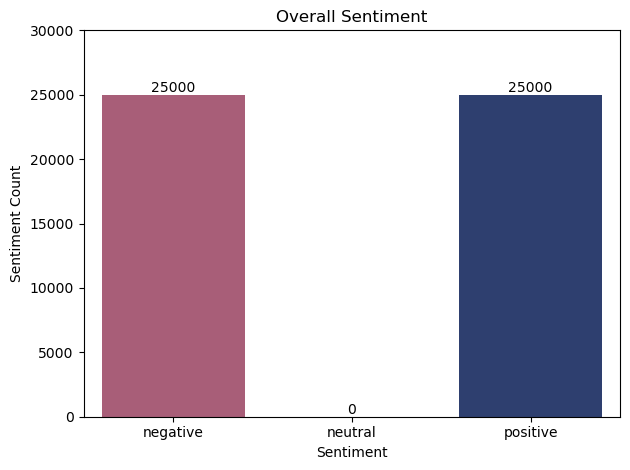

In [13]:
sentiment_counts = (
    IMDB_Dataset_df["sentiment"]
    .value_counts()
    .reindex(LABELS, fill_value=0)
    .rename_axis("sentiment")
    .reset_index(name="count")
)

ax = sns.barplot(
    data=sentiment_counts,
    x="sentiment",
    y="count",
    order=LABELS,
    hue="sentiment",
    palette={
        "negative": "#B45274",
        "neutral": "#9B9797",
        "positive": "#233A7A",
    },
    legend=False,
)

ax.set(
    title="Overall Sentiment",
    xlabel="Sentiment",
    ylabel="Sentiment Count",
)
for container in ax.containers:
    ax.bar_label(container, fmt="%d")
ax.margins(y=0.2)

plt.tight_layout()
plt.show()

### Word Cloud

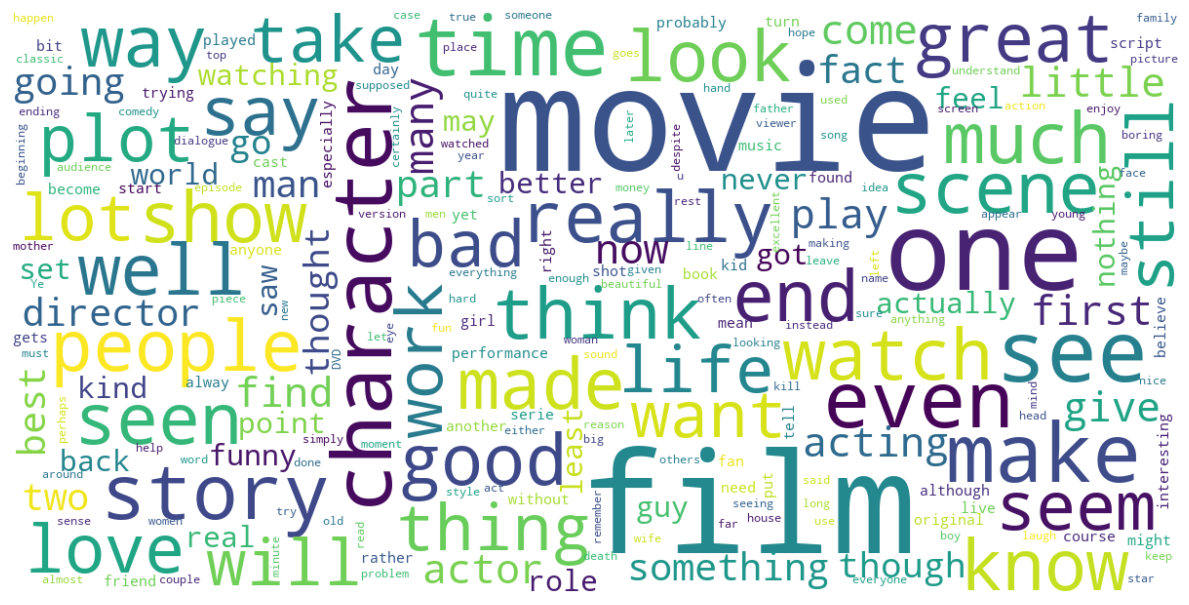

In [14]:
reviews = IMDB_Dataset_df['clean_review'].str.cat(sep=" ")

wordcloud = WordCloud(
    background_color = 'white',
    stopwords = STOPWORDS,
    max_words = 300,
    max_font_size = 50,
    scale = 3,
    random_state = 1
).generate(reviews)

plt.figure(figsize=(12,12))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')

plt.tight_layout()
plt.show()

### Train/Test Split

In [15]:
train, test = train_test_split(IMDB_Dataset_df, test_size=0.2, random_state=42,
                               stratify=IMDB_Dataset_df["sentiment"])

y_train = train['sentiment'].to_numpy()
y_test = test['sentiment'].to_numpy()

print(len(train), 'train data; ', len(test), 'test data')

results, preds = {}, {}

40000 train data;  10000 test data


In [16]:
HUMAN_LABELS = ["negative", "positive"]

def evaluate(name, y_pred, labels=HUMAN_LABELS):
    """
    Evaluate a model, store its prediction metrics and predictions, and
    display a classification report and confusion matrix.
    """
    y_pred = np.asarray(y_pred)
    preds[name] = y_pred

    results[name] = {
        "accuracy": accuracy_score(y_test, y_pred),
        "macro_f1": f1_score(
            y_test,
            y_pred,
            labels=HUMAN_LABELS,
            average="macro",
            zero_division=0,
        ),
    }

    print(f"==={name}===")
    print(classification_report(
        y_test,
        y_pred,
        labels=labels,
        digits=3,
        zero_division=0,
    ))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=labels,
        cmap="Blues",
    )
    plt.title(f"Confusion Matrix: {name}")
    plt.show()

### Vader

In [17]:
vader = SentimentIntensityAnalyzer()

def vader_label(text, threshold=0.2):
    c = vader.polarity_scores(text)['compound']

    if c >= threshold:
        return "positive"
    elif c <= -threshold:
        return "negative"
    else:
        return "neutral"

===VADER===
              precision    recall  f1-score   support

    negative      0.803     0.512     0.626      5000
     neutral      0.000     0.000     0.000         0
    positive      0.657     0.854     0.742      5000

    accuracy                          0.683     10000
   macro avg      0.487     0.455     0.456     10000
weighted avg      0.730     0.683     0.684     10000



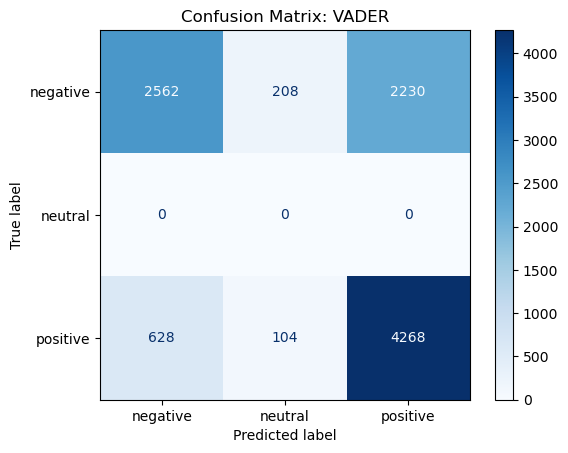

In [18]:
evaluate("VADER", test['clean_review'].apply(vader_label), labels=LABELS)

### NLTK & Naive Bayes

In [19]:
tokenizer = TweetTokenizer(preserve_case=False, reduce_len=True, strip_handles=True)

KEEP = {"no", "nor", "not", "very", "too", "against"}
STOP = {w for w in stopwords.words("english") if w not in KEEP and "n't" not in w}

def review_tokens(text):
    toks = tokenizer.tokenize(text)
    toks = mark_negation(toks)
    return [t for t in toks
            if t.replace("_NEG", "") not in STOP and re.search(r"\w", t)]

print(review_tokens("I do NOT like this movie, but the acting was excellent!!!"))

['not', 'like_NEG', 'movie_NEG', ',_NEG', 'acting_NEG', 'excellent_NEG']


In [20]:
train_tokens = [review_tokens(t) for t in train['clean_review']]
test_tokens = [review_tokens(t) for t in test['clean_review']]

In [21]:
freq = FreqDist(w for toks in train_tokens for w in toks)
VOCAB = {w for w, _ in freq.most_common(3000)}

In [22]:
def nltk_features(tokens):
    return {w: True for w in set(tokens) if w in VOCAB}

In [23]:
Train_set = [(nltk_features(t), y) for t, y in zip(train_tokens, y_train)]

nb = NaiveBayesClassifier.train(Train_set)
nb.show_most_informative_features(10)

Most Informative Features
                   waste = True           negati : positi =     14.8 : 1.0
               waste_NEG = True           negati : positi =     13.8 : 1.0
                  seagal = True           negati : positi =     12.1 : 1.0
               redeeming = True           negati : positi =     12.0 : 1.0
                 unfunny = True           negati : positi =     11.8 : 1.0
                  insult = True           negati : positi =     10.5 : 1.0
                   awful = True           negati : positi =     10.2 : 1.0
              amateurish = True           negati : positi =     10.0 : 1.0
               atrocious = True           negati : positi =      9.9 : 1.0
                  poorly = True           negati : positi =      9.8 : 1.0


===NLTK + Naive Bayes===
              precision    recall  f1-score   support

    negative      0.798     0.894     0.843      5000
    positive      0.879     0.773     0.823      5000

    accuracy                          0.833     10000
   macro avg      0.838     0.833     0.833     10000
weighted avg      0.838     0.833     0.833     10000



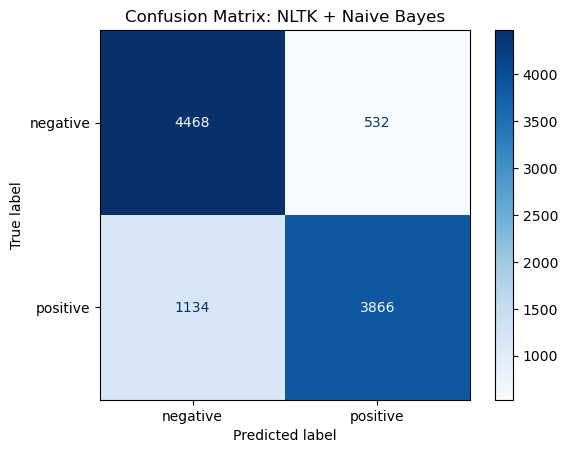

In [24]:
evaluate("NLTK + Naive Bayes", [nb.classify(nltk_features(t)) for t in test_tokens])

In [25]:
results

{'VADER': {'accuracy': 0.683, 'macro_f1': 0.6840155032536317},
 'NLTK + Naive Bayes': {'accuracy': 0.8334, 'macro_f1': 0.8327940389087669}}